# Task 4: NLP Sentiment Classification on Customer Reviews (TF-IDF)

**Goal:** Build a text classifier that decides whether a review is **positive or negative**, using classic NLP preprocessing, **TF-IDF** features and two models: **Multinomial Naive Bayes** and **Logistic Regression**.

**Pipeline steps**
1. Load a labelled review dataset (2,000 movie reviews) and explore it
2. Preprocess the text: lowercasing, HTML/punctuation removal, stopword removal, lemmatization
3. Convert the text to numbers with `TfidfVectorizer(max_features=5000)`
4. Train Multinomial Naive Bayes and Logistic Regression
5. Benchmark accuracy (test set and cross-validation), precision, recall, F1, ROC-AUC and confusion matrices
6. Inspect the words that drive each prediction
7. Test which preprocessing choices matter
8. Provide a `predict_sentiment()` function and an interactive test helper for custom phrases

**Tools:** Python, NLTK, TfidfVectorizer, Naive Bayes, Scikit-Learn, Seaborn

In [1]:
import re
from functools import lru_cache
from pathlib import Path

import nltk
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.model_selection import cross_val_score, train_test_split
from sklearn.naive_bayes import MultinomialNB
from sklearn.pipeline import Pipeline

for resource in ["stopwords", "wordnet", "omw-1.4", "movie_reviews"]:
    nltk.download(resource, quiet=True)

RANDOM_STATE = 42
sns.set_theme(style="whitegrid")

RESULTS = Path("../results")
RESULTS.mkdir(parents=True, exist_ok=True)


def save_fig(name):
    """Save the current figure into the results folder."""
    plt.savefig(RESULTS / name, dpi=150, bbox_inches="tight")

## 1. Load the dataset

The data is read from `data/movie_reviews.csv`: the NLTK *movie_reviews* corpus (Pang & Lee), 1,000 positive and 1,000 negative full-length reviews. If the file is missing, it is built once from the NLTK corpus. To use another dataset (for example the starter file from the task page), put it in `data/` with a text column and a label column and adjust the code below.

In [2]:
DATA_PATH = Path("../data/movie_reviews.csv")

if not DATA_PATH.exists():
    from nltk.corpus import movie_reviews

    DATA_PATH.parent.mkdir(parents=True, exist_ok=True)
    rows = [
        (movie_reviews.raw(file_id), category)
        for category in movie_reviews.categories()
        for file_id in movie_reviews.fileids(category)
    ]
    pd.DataFrame(rows, columns=["review", "sentiment"]).to_csv(DATA_PATH, index=False)

df = pd.read_csv(DATA_PATH)
df["label"] = (df["sentiment"] == "pos").astype(int)  # 1 = positive, 0 = negative

print("Shape:", df.shape)
print("Missing values:", int(df[["review", "sentiment"]].isna().sum().sum()))
print("Duplicate reviews:", int(df["review"].duplicated().sum()))
print("\nClass distribution:")
print(df["sentiment"].value_counts())
print("\nExample review (first 400 characters):")
print(df["review"].iloc[0][:400])

Shape: (2000, 3)
Missing values: 0
Duplicate reviews: 0

Class distribution:
sentiment
neg    1000
pos    1000
Name: count, dtype: int64

Example review (first 400 characters):
plot : two teen couples go to a church party , drink and then drive . 
they get into an accident . 
one of the guys dies , but his girlfriend continues to see him in her life , and has nightmares . 
what's the deal ? 
watch the movie and " sorta " find out . . . 
critique : a mind-fuck movie for the teen generation that touches on a very cool idea , but presents it in a very bad package . 
which i


## 2. Exploration

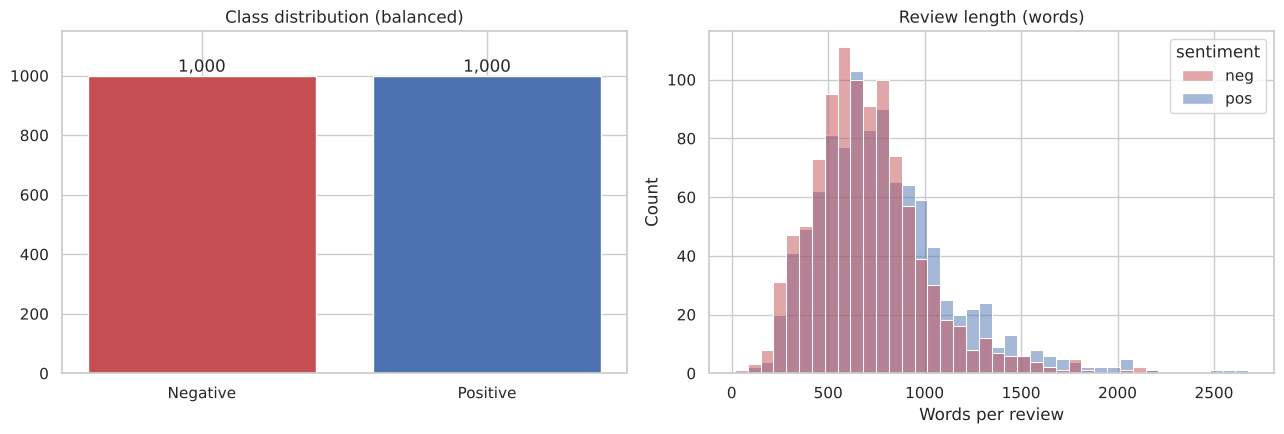

            count   mean    std    min    25%    50%    75%     max
sentiment                                                          
neg        1000.0  706.0  297.0   17.0  510.0  668.0  848.0  2181.0
pos        1000.0  787.0  353.0  130.0  544.0  732.0  957.0  2678.0


In [3]:
df["n_words"] = df["review"].str.split().str.len()

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

counts = df["sentiment"].value_counts()
axes[0].bar(["Negative", "Positive"], [counts["neg"], counts["pos"]], color=["#c44e52", "#4c72b0"])
for i, value in enumerate([counts["neg"], counts["pos"]]):
    axes[0].text(i, value, f"{value:,}", ha="center", va="bottom")
axes[0].set_title("Class distribution (balanced)")
axes[0].set_ylim(0, counts.max() * 1.15)

sns.histplot(data=df, x="n_words", hue="sentiment", bins=40, palette={"neg": "#c44e52", "pos": "#4c72b0"},
             ax=axes[1])
axes[1].set_title("Review length (words)")
axes[1].set_xlabel("Words per review")

plt.tight_layout()
save_fig("eda_reviews.png")
plt.show()

print(df.groupby("sentiment")["n_words"].describe().round(0))

**Observations:** the two classes are perfectly balanced, so **accuracy is a fair metric** here (unlike in the churn task). Reviews are long (about 750 words on average), and positive and negative reviews have a similar length distribution, so length alone does not reveal the sentiment.

## 3. Text preprocessing

Each review is cleaned in these steps:
1. **Lowercase** the text
2. **Remove HTML tags** and expand contractions (`don't` becomes `do not`)
3. **Keep only letters** (removes punctuation and digits) and split into tokens
4. **Remove stopwords** (`the`, `is`, `of`, ...), but **keep negations** such as `not`, `no` and `never`. NLTK's default stopword list contains them, but `not good` and `good` mean the opposite
5. **Lemmatize** with WordNet (`movies` becomes `movie`, `running` becomes `run`)

In [4]:
STOP_WORDS = frozenset(stopwords.words("english"))
NEGATIONS = frozenset({"no", "nor", "not", "never", "none", "nothing", "neither", "nowhere", "cannot"})
lemmatizer = WordNetLemmatizer()


@lru_cache(maxsize=None)
def lemmatize(word):
    """Lemmatize as verb first, then as noun (cached: the vocabulary repeats a lot)."""
    return lemmatizer.lemmatize(lemmatizer.lemmatize(word, "v"), "n")


def preprocess_text(text, keep_negations=True):
    """Clean one review: lowercase, strip HTML/punctuation, drop stopwords, lemmatize."""
    text = re.sub(r"<[^>]+>", " ", str(text).lower())
    text = text.replace("can't", "cannot").replace("won't", "will not")
    text = re.sub(r"n't\b", " not", text)
    tokens = re.findall(r"[a-z]+", text)

    stop_words = STOP_WORDS - NEGATIONS if keep_negations else STOP_WORDS
    tokens = [t for t in tokens if len(t) > 1 and t not in stop_words]
    return " ".join(lemmatize(t) for t in tokens)


sample = "<br />I DON'T think the movies were good... The actors are running out of ideas!!!"
print("Before:", sample)
print("After: ", preprocess_text(sample))
print("\nStopwords in the NLTK list that are negations (kept on purpose):",
      sorted(NEGATIONS & STOP_WORDS))

Before: <br />I DON'T think the movies were good... The actors are running out of ideas!!!


After:  not think movie good actor run idea

Stopwords in the NLTK list that are negations (kept on purpose): ['no', 'nor', 'not']


## 4. Train/test split and TF-IDF features

The split is **stratified** (80/20). The TF-IDF vectorizer is **fitted on the training reviews only**. It keeps the 5,000 most frequent terms and weights each term by how characteristic it is for a review (frequent in the review, rare across all reviews).

In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    df["review"], df["label"], test_size=0.20, random_state=RANDOM_STATE, stratify=df["label"]
)

train_clean = [preprocess_text(t) for t in X_train]
test_clean = [preprocess_text(t) for t in X_test]

tfidf = TfidfVectorizer(max_features=5000)
X_train_tfidf = tfidf.fit_transform(train_clean)
X_test_tfidf = tfidf.transform(test_clean)

sparsity = 1 - X_train_tfidf.nnz / (X_train_tfidf.shape[0] * X_train_tfidf.shape[1])
print(f"Train: {len(X_train)} reviews | Test: {len(X_test)} reviews")
print(f"TF-IDF matrix (train): {X_train_tfidf.shape[0]} reviews x {X_train_tfidf.shape[1]} terms, "
      f"{sparsity:.1%} zeros")

Train: 1600 reviews | Test: 400 reviews
TF-IDF matrix (train): 1600 reviews x 5000 terms, 95.7% zeros


## 5. Train and benchmark the models

In [6]:
models = {
    "Multinomial Naive Bayes": MultinomialNB(),
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=RANDOM_STATE),
}

rows = {}
predictions = {}
for name, model in models.items():
    model.fit(X_train_tfidf, y_train)
    predictions[name] = model.predict(X_test_tfidf)
    probabilities = model.predict_proba(X_test_tfidf)[:, 1]

    cv = cross_val_score(
        Pipeline([("tfidf", TfidfVectorizer(max_features=5000)), ("model", model)]),
        train_clean, y_train, cv=5, scoring="accuracy",
    )
    rows[name] = {
        "Test accuracy": accuracy_score(y_test, predictions[name]),
        "Precision": precision_score(y_test, predictions[name]),
        "Recall": recall_score(y_test, predictions[name]),
        "F1": f1_score(y_test, predictions[name]),
        "ROC-AUC": roc_auc_score(y_test, probabilities),
        "CV accuracy (mean)": cv.mean(),
        "CV accuracy (std)": cv.std(),
    }

results = pd.DataFrame(rows).T.rename_axis("Model")
display(results.round(4))
print(f"Majority-class baseline accuracy: {max(y_test.mean(), 1 - y_test.mean()):.3f}")

,Test accuracy,Precision,Recall,F1,ROC-AUC,CV accuracy (mean),CV accuracy (std)
Model,,,,,,,
Multinomial Naive Bayes,0.810,0.8333,0.775,0.8031,0.8912,0.82,0.0196
Logistic Regression,0.835,0.8131,0.870,0.8406,0.9146,0.84,0.0166


Majority-class baseline accuracy: 0.500


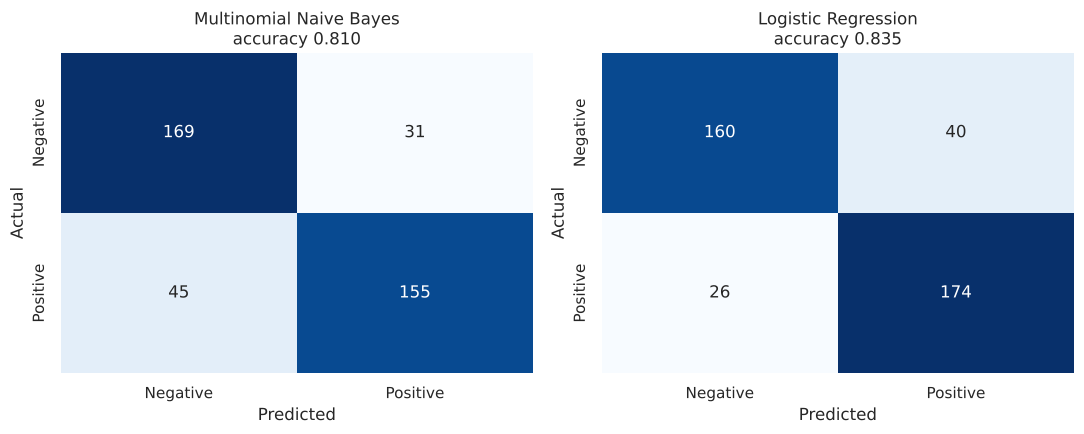

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, (name, y_pred) in zip(axes, predictions.items()):
    cm = confusion_matrix(y_test, y_pred)
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
                xticklabels=["Negative", "Positive"], yticklabels=["Negative", "Positive"])
    ax.set_title(f"{name}\naccuracy {accuracy_score(y_test, y_pred):.3f}")
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")
plt.tight_layout()
save_fig("confusion_matrices.png")
plt.show()

## 6. Which words drive the predictions?

For Logistic Regression, the coefficients show how strongly each word pushes a review towards positive or negative. For Naive Bayes, the difference of the class log-probabilities does the same.

,LR positive,LR negative,NB positive,NB negative
0,great,bad,mulan,seagal
1,war,bore,flynt,worst
2,also,worst,truman,waste
3,performance,plot,shrek,jawbreaker
4,see,waste,damon,schumacher
5,life,no,lebowski,martha
6,well,suppose,crowe,ridiculous
7,excellent,not,outstanding,stupid
8,best,nothing,argento,prinze
9,perfect,attempt,excellent,poorly


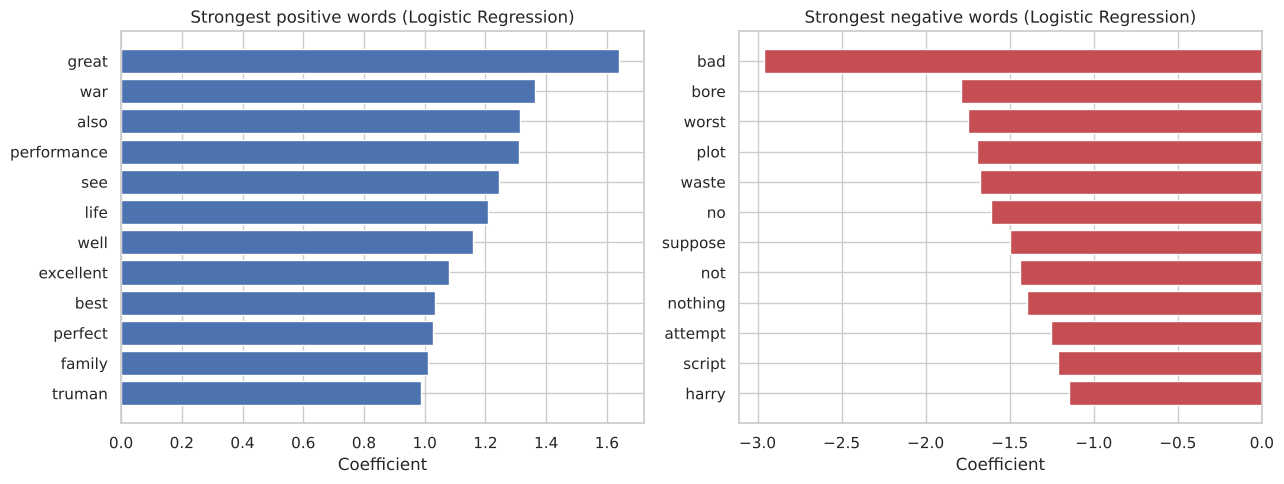

In [8]:
terms = np.array(tfidf.get_feature_names_out())
lr_scores = models["Logistic Regression"].coef_[0]
nb = models["Multinomial Naive Bayes"]
nb_scores = nb.feature_log_prob_[1] - nb.feature_log_prob_[0]

top_n = 12
order = np.argsort(lr_scores)
top_table = pd.DataFrame({
    "LR positive": terms[order[::-1][:top_n]],
    "LR negative": terms[order[:top_n]],
    "NB positive": terms[np.argsort(nb_scores)[::-1][:top_n]],
    "NB negative": terms[np.argsort(nb_scores)[:top_n]],
})
display(top_table)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
positive_idx, negative_idx = order[::-1][:top_n], order[:top_n]
axes[0].barh(terms[positive_idx][::-1], lr_scores[positive_idx][::-1], color="#4c72b0")
axes[0].set_title("Strongest positive words (Logistic Regression)")
axes[1].barh(terms[negative_idx][::-1], lr_scores[negative_idx][::-1], color="#c44e52")
axes[1].set_title("Strongest negative words (Logistic Regression)")
for ax in axes:
    ax.set_xlabel("Coefficient")
plt.tight_layout()
save_fig("top_words.png")
plt.show()

## 7. Do the preprocessing choices matter?

Four variants are compared with **5-fold cross-validation on the training set** (the test set is not used for these decisions). The final setup is the one with cleaned text and negations kept.

In [9]:
def cv_accuracy(texts, model, ngram_range=(1, 1)):
    pipe = Pipeline([
        ("tfidf", TfidfVectorizer(max_features=5000, ngram_range=ngram_range)),
        ("model", model),
    ])
    scores = cross_val_score(pipe, texts, y_train, cv=5, scoring="accuracy")
    return f"{scores.mean():.3f} +/- {scores.std():.3f}"


variants = {
    "Raw text (no cleaning)": (list(X_train), (1, 1)),
    "Cleaned, negations removed": ([preprocess_text(t, keep_negations=False) for t in X_train], (1, 1)),
    "Cleaned, negations kept (final)": (train_clean, (1, 1)),
    "Cleaned, negations kept + bigrams": (train_clean, (1, 2)),
}

experiment_rows = {}
for variant, (texts, ngrams) in variants.items():
    experiment_rows[variant] = {
        "Naive Bayes": cv_accuracy(texts, MultinomialNB(), ngrams),
        "Logistic Regression": cv_accuracy(
            texts, LogisticRegression(max_iter=1000, random_state=RANDOM_STATE), ngrams),
    }

display(pd.DataFrame(experiment_rows).T.rename_axis("Preprocessing variant (CV accuracy)"))

,Naive Bayes,Logistic Regression
Preprocessing variant (CV accuracy),,
Raw text (no cleaning),0.804 +/- 0.023,0.816 +/- 0.026
"Cleaned, negations removed",0.824 +/- 0.022,0.837 +/- 0.022
"Cleaned, negations kept (final)",0.820 +/- 0.020,0.840 +/- 0.017
"Cleaned, negations kept + bigrams",0.824 +/- 0.024,0.842 +/- 0.020


## 8. `predict_sentiment()`: test your own phrases

The function cleans the phrase exactly like the training data, converts it with the fitted TF-IDF vectorizer and returns the predicted sentiment with its confidence. If none of the words are known to the model, it reports `unknown` instead of guessing.

In [10]:
final_model = models["Logistic Regression"]


def predict_sentiment(text, model=final_model, vectorizer=tfidf):
    """Classify a custom phrase. Returns (sentiment, confidence)."""
    if not isinstance(text, str) or not text.strip():
        raise ValueError("Please provide a non-empty text")
    features = vectorizer.transform([preprocess_text(text)])
    if features.nnz == 0:
        return "unknown", 0.0
    positive = model.predict_proba(features)[0, 1]
    return ("positive", positive) if positive >= 0.5 else ("negative", 1 - positive)


def test_phrases(phrases):
    """Predict several phrases and show them in a table."""
    rows = []
    for phrase in phrases:
        sentiment, confidence = predict_sentiment(phrase)
        rows.append({"Phrase": phrase, "Sentiment": sentiment, "Confidence": round(confidence, 2)})
    return pd.DataFrame(rows)


demo_phrases = [
    "An absolutely wonderful film with brilliant acting and a moving story",
    "This was a waste of time, boring and predictable",
    "I loved every minute of it",
    "The movie was not good at all",
    "Not bad, actually quite enjoyable",
    "The plot was dull but the acting was great",
    "xqzv wvut plmk",
]
display(test_phrases(demo_phrases))

,Phrase,Sentiment,Confidence
0,An absolutely wonderful film with brilliant ac...,positive,0.70
1,"This was a waste of time, boring and predictable",negative,0.87
2,I loved every minute of it,positive,0.51
3,The movie was not good at all,negative,0.68
4,"Not bad, actually quite enjoyable",negative,0.65
5,The plot was dull but the acting was great,negative,0.63
6,xqzv wvut plmk,unknown,0.00


**Edit the list and run it again** to try your own phrases:

In [11]:
my_phrases = [
    "I would happily watch this again",
    "Terrible script and even worse acting",
]
display(test_phrases(my_phrases))

,Phrase,Sentiment,Confidence
0,I would happily watch this again,negative,0.56
1,Terrible script and even worse acting,negative,0.83


### Interactive helper

`interactive_test()` asks for phrases one by one and prints the prediction (an empty line stops it). It needs keyboard input, so it works in Jupyter, VS Code or Colab; call it in a new cell.

In [12]:
def interactive_test():
    """Type a phrase, get the sentiment; submit an empty line to stop."""
    while True:
        text = input("Enter a review (empty line to stop): ")
        if not text.strip():
            print("Done.")
            break
        sentiment, confidence = predict_sentiment(text)
        print(f"  -> {sentiment} (confidence {confidence:.0%})")


# interactive_test()   # uncomment and run to try your own phrases

## 9. Testing on the starter file (product reviews)

The task's starter file `data/sentiment_reviews.csv` contains only **10 short product reviews** (5 positive, 4 negative, 1 neutral). That is far too little to train or benchmark a model, so it is used as a **small extra test on a different kind of text**: the models trained on movie reviews are applied to product reviews. The neutral review is skipped, because the models are binary. Nothing in this notebook was tuned on this file, and with only 9 reviews the accuracy is a rough indication at best.

In [13]:
STARTER_PATH = Path("../data/sentiment_reviews.csv")

if STARTER_PATH.exists():
    starter = pd.read_csv(STARTER_PATH)
    print("Starter file:", starter.shape, starter["sentiment"].value_counts().to_dict())
    starter = starter[starter["sentiment"].isin(["positive", "negative"])].copy()

    rows = []
    for text, actual in zip(starter["review_text"], starter["sentiment"]):
        predicted, confidence = predict_sentiment(text)
        rows.append({"Review": text, "Actual": actual, "Predicted": predicted,
                     "Confidence": round(confidence, 2), "Correct": actual == predicted})
    starter_results = pd.DataFrame(rows)
    display(starter_results)

    print(f"\nLogistic Regression: {starter_results['Correct'].mean():.3f} accuracy "
          f"({int(starter_results['Correct'].sum())} of {len(starter_results)})")
    nb_correct = sum(
        predict_sentiment(text, model=models["Multinomial Naive Bayes"])[0] == actual
        for text, actual in zip(starter["review_text"], starter["sentiment"])
    )
    print(f"Naive Bayes: {nb_correct / len(starter):.3f} accuracy ({nb_correct} of {len(starter)})")

    # How many words of these reviews does the movie-review vocabulary know?
    tokens = [t for text in starter["review_text"] for t in preprocess_text(text).split()]
    known = [t for t in tokens if t in tfidf.vocabulary_]
    print(f"\nWords known to the model's vocabulary: {len(known)} of {len(tokens)} "
          f"({len(known) / len(tokens):.0%})")
    print("Examples of unknown words:", sorted(set(tokens) - set(known))[:12])
else:
    print("Starter file not found: skipping this section.")

Starter file: (10, 3) {'positive': 5, 'negative': 4, 'neutral': 1}


,Review,Actual,Predicted,Confidence,Correct
0,"The product quality is exceptional, exceeded a...",positive,positive,0.55,True
1,Terrible customer service and the item arrived...,negative,negative,0.52,True
2,"Absolutely love this! Easy to setup, robust, a...",positive,positive,0.62,True
3,Stopped working after two days. Extremely disa...,negative,positive,0.61,False
4,Customer support helped resolve my setup quest...,positive,negative,0.50,False
5,Delivery was slow and package was missing one ...,negative,positive,0.53,False
6,Clean interface and intuitive controls. Highly...,positive,positive,0.66,True
7,"Not worth the money, plenty of better alternat...",negative,positive,0.50,False
8,Great value and durable build. Would definitel...,positive,positive,0.69,True



Logistic Regression: 0.556 accuracy (5 of 9)
Naive Bayes: 0.667 accuracy (6 of 9)

Words known to the model's vocabulary: 53 of 63 (84%)
Examples of unknown words: ['adapter', 'alternative', 'durable', 'exceed', 'flawlessly', 'interface', 'intuitive', 'purchase', 'robust']


## 10. Conclusion

### Results
- **Logistic Regression is the better model:** test accuracy **0.835** vs. 0.810 for Multinomial Naive Bayes, ROC-AUC 0.915 vs. 0.891, and cross-validated accuracy 0.84 vs. 0.82 (standard deviation about 0.02). The classes are balanced, so the majority-class baseline is only 0.50. Naive Bayes is slightly more precise (0.83 vs. 0.81) but finds fewer positive reviews (recall 0.78 vs. 0.87).
- With only 400 test reviews, one review is worth 0.25 percentage points and the gap between the models is about as large as the cross-validation noise, so Logistic Regression is *modestly* better rather than clearly better.
- **Preprocessing helps, but not every detail can be proven:** cleaning the text improves cross-validated accuracy by about 2 points over raw text (Naive Bayes 0.804 to 0.82, Logistic Regression 0.816 to 0.84). Keeping negations instead of removing them, or adding bigrams, made no measurable difference here (all within noise). Keeping negations is still the safer choice in principle.

### What the models learned
- Logistic Regression picks up sensible sentiment words: *great*, *excellent*, *perfect*, *best* on the positive side and *bad*, *bore*, *worst*, *waste*, *not*, *no* on the negative side.
- It also relies on **dataset-specific words** such as movie titles and names (*truman*, *harry*, *mulan*, *seagal*, *shrek*) and topics (*war*, *family*). The corpus contains several reviews per movie, so the models partly memorize movies. The top words of Naive Bayes are dominated by such names.

### Test on the starter file (product reviews)
- The starter file has only 10 reviews (9 positive or negative), which is too little to train or benchmark a model, so it served as an extra test of the movie-trained models on a different kind of text.
- **The models do not transfer well:** Logistic Regression got 5 of 9 right (0.56) and Naive Bayes 6 of 9 (0.67), close to guessing, and all confidences lie between 0.50 and 0.69. With 9 reviews these numbers are only indicative.
- Unknown words are **not** the main reason: 84% of the words in these reviews are in the model's vocabulary. More likely, the sentiment cues of product reviews ("stopped working", "slow", "missing", "better alternatives") rarely act as sentiment cues in movie reviews, and the reviews are very short, so the model sees little evidence.
- Conclusion: for product reviews, the model should be trained on product reviews.

### `predict_sentiment()`: strengths and limits
- Clear phrases work well (for example "a waste of time, boring and predictable" is negative with 87% confidence), and phrases without any known word are reported as `unknown`.
- Some short or subtle phrases are wrong: "Not bad, actually quite enjoyable" is classified as negative, and "I would happily watch this again" as negative with low confidence. The models were trained on 1,600 long reviews (about 750 words each), short phrases give them very few features, and a bag-of-words model ignores word order, so "not bad" is read as "not" plus "bad". A confidence close to 0.5 signals an unreliable prediction.

### Next steps
- Train on a larger set of **short product reviews** (for example Amazon or Yelp reviews) to match the domain of the starter file, and compare with word pairs (bigrams) or a pretrained transformer model, which handles negation and short texts better.
- Split the cross-validation by movie (`GroupKFold`) or remove proper nouns, to measure how well the model generalizes to unseen movies instead of memorized ones.